In [56]:
import pandas as pd

'''
= encoding 방식
utf-8 : 웹, 리눅스, 맥 등에서 만든 데이터 
utf-8-sig : utf-8 + BOM(엑셀에서 작업)
cp949 : 윈도우 엑셀에서 작업한 데이터 
euc-kr : 오래된 사이트나 일부공공기관 파일
utf=16 : 2byte 기반 유니코드 형태로 저장(엑셀에서)
latin1(iso-8859-1) : 서유럽 문자용
'''

df= pd.read_csv('./Data-Pandas/seoul.csv',encoding='cp949')
df.head()

,날짜,지점,평균기온(℃),최저기온(℃),최고기온(℃)
0,\t1907-10-01,108.0,13.5,7.9,20.7
1,\t1907-10-02,108.0,16.2,7.9,22.0
2,\t1907-10-03,108.0,16.2,13.1,21.3
3,\t1907-10-04,108.0,16.5,11.2,22.0
4,\t1907-10-05,108.0,17.6,10.9,25.4


In [57]:
# 컬럼명만 추출
print(df.columns)

Index(['날짜', '지점', '평균기온(℃)', '최저기온(℃)', '최고기온(℃)'], dtype='str')


In [58]:
# 데이터 한 줄씩 출력
count = 0
for index, row in df.iterrows():
    count +=1
    # print(index, row, type(row))
    
count

40222

In [59]:
df.shape

(40222, 5)

In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40222 entries, 0 to 40221
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   날짜       40222 non-null  str    
 1   지점       40221 non-null  float64
 2   평균기온(℃)  39465 non-null  float64
 3   최저기온(℃)  39464 non-null  float64
 4   최고기온(℃)  39463 non-null  float64
dtypes: float64(4), str(1)
memory usage: 1.5 MB


* 서울의 최고기온이 가장 높았던 날은?

In [61]:
high = -999        # 지금까지의 최고 기온 (아주 낮은 값에서 시작)
high_date = ''     # 그 기온이 나온 날짜

for i in range(len(df)):               # i = 0, 1, 2, ..., 40221 (줄 번호)
    temp = df.iloc[i, 4]    # i 번째 줄의 최고기온 꺼내기
    if pd.notnull(temp):
        if temp > high:                    # 지금까지의 기록보다 높으면
           high = temp                    # 기록 갱신
           high_date = df.loc[i, '날짜']  # 날짜도 함께 기억

print(high_date, high)   # 2018-08-01 39.6


	2018-08-01 39.6


In [62]:
# 최고기온이 가장 높은 행 찾기
max_row = df.loc[df['최고기온(℃)'].idxmax()]
max_row

날짜         \t2018-08-01
지점                108.0
평균기온(℃)            33.6
최저기온(℃)            27.8
최고기온(℃)            39.6
Name: 40051, dtype: object

* 내 생일의 평균 기온데이터를 라인그래프로 그리기(최고기온)

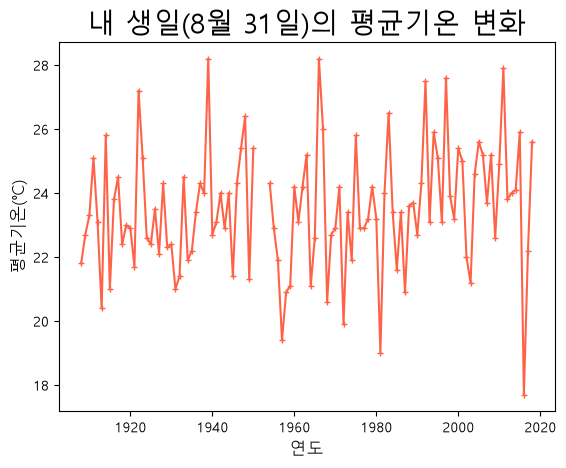

In [63]:
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc

# 한글 글꼴 설정 (그래프의 한글이 깨지지 않게)
font_name = font_manager.FontProperties(fname='./Data-Pandas/malgun.ttf').get_name()
rc('font', family=font_name)
plt.rcParams['axes.unicode_minus'] = False   # 마이너스(-) 부호 깨짐 방지

# ★ 내 생일로 바꾸기 (월, 일)
month = 8
day = 31

# 날짜 앞의 탭(\t)을 떼고 날짜 자료형으로 변환
df['날짜'] = pd.to_datetime(df['날짜'].str.strip())

# 매년 내 생일인 행만 고르기 : 월이 같고(그리고) 일이 같은 행
mask = (df['날짜'].dt.month == month) & (df['날짜'].dt.day == day)
df_birth = df[mask]

# 선 그래프 : x = 연도, y = 그날의 평균기온 (연도 추출)
plt.figure()
plt.plot(df_birth['날짜'].dt.year, df_birth['평균기온(℃)'], marker='+', markersize=4, color='tomato')

plt.title(f'내 생일({month}월 {day}일)의 평균기온 변화', size=20)
plt.xlabel('연도', size=12)
plt.ylabel('평균기온(℃)', size=12)
plt.show()


* 내 생일의 최고기온(빨간색), 최저기온(파란색)으로 그래프 그리기



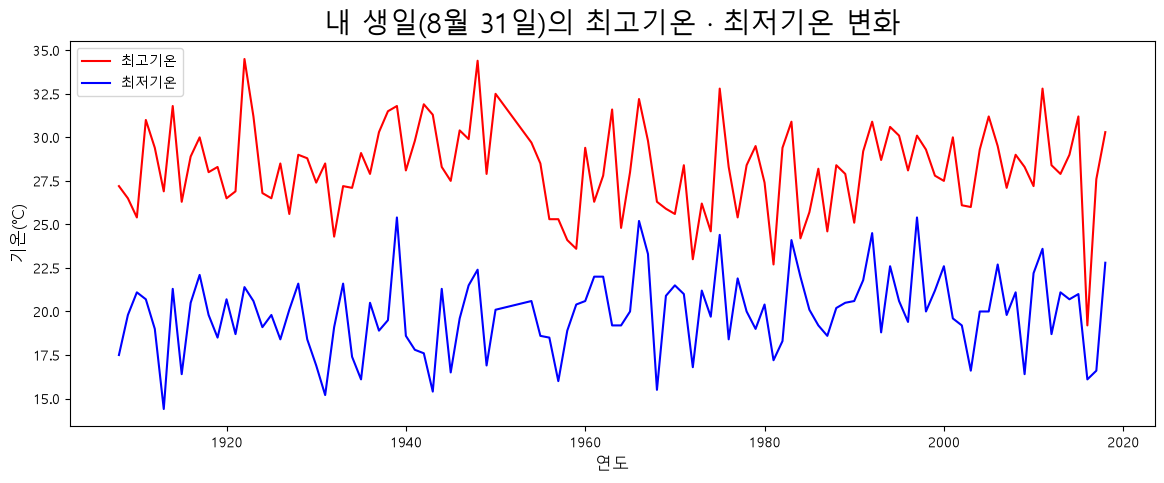

In [71]:
# ★ 내 생일 (월, 일)
month = 8
day = 31

# 날짜 앞의 탭(\t)을 떼고 날짜 자료형으로 변환 (여러 번 실행해도 괜찮게 astype(str) 사용)
df['날짜'] = pd.to_datetime(df['날짜'].astype(str).str.strip())

# 결측치 제거
df = df.dropna(subset=['최고기온(℃)'])
df = df.dropna(subset=['최저기온(℃)'])

# 기온 숫자 변환, errors='coerce' : 변환되지 않는 값은 NaN으로 변환해라
df['최고기온(℃)'] = pd.to_numeric(df['최고기온(℃)'],errors='coerce')
df['최저기온(℃)'] = pd.to_numeric(df['최저기온(℃)'],errors='coerce')

# 매년 내 생일인 행만 고르기
mask = (df['날짜'].dt.month == month) & (df['날짜'].dt.day == day)
df_birth = df[mask]

# 선 그래프 : 같은 도화지에 plot 을 두 번 → 선 2개
plt.figure(figsize=(14, 5))
plt.plot(df_birth['날짜'].dt.year, df_birth['최고기온(℃)'], color='red', label='최고기온')
plt.plot(df_birth['날짜'].dt.year, df_birth['최저기온(℃)'], color='blue', label='최저기온')

plt.title(f'내 생일({month}월 {day}일)의 최고기온 · 최저기온 변화', size=20)
plt.xlabel('연도', size=12)
plt.ylabel('기온(℃)', size=12)
plt.legend(loc='best')   # 각 plot 의 label 을 모아 범례로 표시
plt.show()


